# Week 5 — Evaluation & Error Analysis

## Objective

This notebook evaluates the Week 4 hybrid NLP exam-answer grading model
on the held-out EngSAF test set.

The evaluation focuses on:

- Quantitative performance
- Confusion matrix analysis
- Error analysis
- Failure cases
- Robustness analysis



## Setup

Import the required libraries and define the paths for the test dataset and trained models. :::

In [53]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    cohen_kappa_score,
    f1_score,
    mean_absolute_error,
    recall_score,
)

# Project paths
BACKEND_DIR = Path("..")
DATA_DIR = BACKEND_DIR / "data"
MODELS_DIR = BACKEND_DIR / "models"

TEST_PATH = DATA_DIR / "engsaf_test.csv"
MODEL_PATH = MODELS_DIR / "grader_models.joblib"

print("Test data:", TEST_PATH)
print("Model:", MODEL_PATH)


Test data: ..\data\engsaf_test.csv
Model: ..\models\grader_models.joblib



## Load Test Data

Load the test dataset and inspect its shape and available columns. :::

In [54]:
test_df = pd.read_csv(TEST_PATH)

print("Test set shape:", test_df.shape)
print("\nColumns:")
print(test_df.columns.tolist())


Test set shape: (506, 8)

Columns:
['question', 'student_answer', 'reference_answer', 'mark_scheme', 'score', 'rationale', 'student_answer_clean', 'reference_answer_clean']



## Class Distribution

Map the score labels to their categories and summarize the number and percentage of samples in each class. :::

In [55]:
label_names = {
    0: "Incorrect",
    1: "Partially correct",
    2: "Correct",
}

class_counts = test_df["score"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Label": class_counts.index,
    "Category": class_counts.index.map(label_names),
    "Count": class_counts.values,
    "Percentage": (class_counts.values / len(test_df) * 100).round(2),
})

class_summary


,Label,Category,Count,Percentage
0,0,Incorrect,113,22.33
1,1,Partially correct,191,37.75
2,2,Correct,202,39.92



## Load Trained Models

Load the saved model bundle and display the available items. :::

In [56]:
bundle = joblib.load(MODEL_PATH)

print("Model bundle loaded successfully.")
print("Available items:")
print(list(bundle.keys()))


Model bundle loaded successfully.
Available items:
['embedding_model', 'feature_names', 'tfidf_vectorizer', 'baseline_clf', 'v1_clf', 'v2_model']



## Import Feature Engineering

Import the project’s feature engineering functions and verify that they are available. :::

In [57]:
import sys

sys.path.insert(0, str(BACKEND_DIR / "src"))

from features import TextEncoder, build_features

print("Project feature code imported successfully.")


Project feature code imported successfully.



## Generate Predictions

Create test features, load the trained model, and generate predicted labels and class probabilities for the test set. :::

In [58]:
encoder = TextEncoder(bundle["embedding_model"])

X_test = build_features(
    test_df["student_answer"].tolist(),
    test_df["reference_answer"].tolist(),
    bundle["tfidf_vectorizer"],
    encoder,
)

v2_model = bundle["v2_model"]

y_true = test_df["score"].to_numpy()
y_pred = v2_model.predict(X_test)
y_proba = v2_model.predict_proba(X_test)

print("Feature matrix shape:", X_test.shape)
print("True labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)
print("Predictions generated successfully.")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/12 [00:00<?, ?it/s]

Feature matrix shape: (506, 7)
True labels: (506,)
Predicted labels: (506,)
Predictions generated successfully.



## Model Evaluation

Calculate and display the model's performance using accuracy, Macro-F1, QWK, MAE, and recall for the partially correct class. :::

In [59]:
metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro-F1": f1_score(y_true, y_pred, average="macro"),
    "QWK": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
    "MAE": mean_absolute_error(y_true, y_pred),
    "Partial Recall": recall_score(
        y_true,
        y_pred,
        labels=[1],
        average="macro",
        zero_division=0,
    ),
}

metrics_df = pd.DataFrame(
    {
        "Metric": metrics.keys(),
        "Value": [round(v, 4) for v in metrics.values()],
    }
)

metrics_df


,Metric,Value
0,Accuracy,0.5257
1,Macro-F1,0.5005
2,QWK,0.3643
3,MAE,0.5711
4,Partial Recall,0.3770



## Confusion Matrix

Create a confusion matrix to compare the true labels with the model's predicted labels for each class. :::

In [60]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

cm_df = pd.DataFrame(
    cm,
    index=["True: Incorrect (0)", "True: Partial (1)", "True: Correct (2)"],
    columns=["Pred: Incorrect (0)", "Pred: Partial (1)", "Pred: Correct (2)"],
)

cm_df


,Pred: Incorrect (0),Pred: Partial (1),Pred: Correct (2)
True: Incorrect (0),44,34,35
True: Partial (1),26,72,93
True: Correct (2),14,38,150



## Confusion Matrix Visualization

Visualize the confusion matrix as a heatmap to compare the model's predicted labels with the true labels. :::

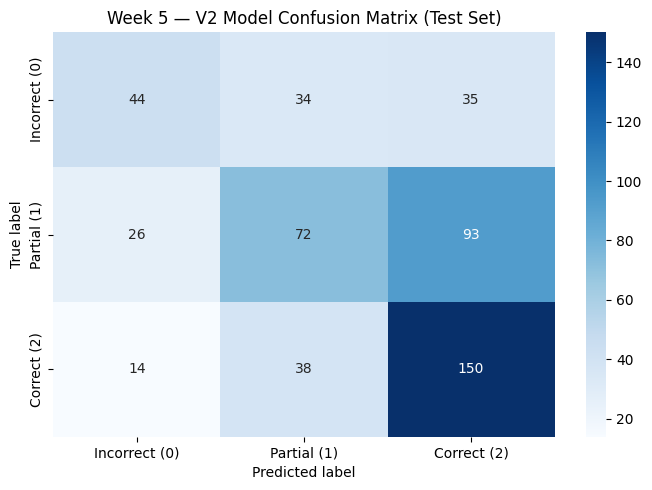

In [61]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Incorrect (0)", "Partial (1)", "Correct (2)"],
    yticklabels=["Incorrect (0)", "Partial (1)", "Correct (2)"],
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Week 5 — V2 Model Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()



## Error Analysis

Identify incorrect predictions, calculate prediction confidence and error rate, and categorize the different types of classification errors. :::

In [62]:
error_df = test_df.copy()

error_df["predicted_score"] = y_pred
error_df["confidence"] = y_proba.max(axis=1)

error_df["error_type"] = np.select(
    [
        (error_df["score"] == 0) & (error_df["predicted_score"] == 1),
        (error_df["score"] == 0) & (error_df["predicted_score"] == 2),
        (error_df["score"] == 1) & (error_df["predicted_score"] == 0),
        (error_df["score"] == 1) & (error_df["predicted_score"] == 2),
        (error_df["score"] == 2) & (error_df["predicted_score"] == 0),
        (error_df["score"] == 2) & (error_df["predicted_score"] == 1),
    ],
    [
        "Incorrect → Partial",
        "Incorrect → Correct",
        "Partial → Incorrect",
        "Partial → Correct",
        "Correct → Incorrect",
        "Correct → Partial",
    ],
    default="Correct prediction",
)

errors_only = error_df[error_df["score"] != error_df["predicted_score"]].copy()

print("Total test examples:", len(error_df))
print("Total errors:", len(errors_only))
print("Error rate:", round(len(errors_only) / len(error_df), 4))

errors_only["error_type"].value_counts()


Total test examples: 506
Total errors: 240
Error rate: 0.4743


error_type
Partial → Correct      93
Correct → Partial      38
Incorrect → Correct    35
Incorrect → Partial    34
Partial → Incorrect    26
Correct → Incorrect    14
Name: count, dtype: int64


## Partial → Correct Errors

Inspect cases where the true label is **Partially correct**, but the model predicts **Correct**. :::

In [63]:
partial_to_correct = errors_only[
    (errors_only["score"] == 1) &
    (errors_only["predicted_score"] == 2)
].copy()

print("Partial → Correct cases:", len(partial_to_correct))

partial_to_correct[
    [
        "question",
        "student_answer",
        "reference_answer",
        "score",
        "predicted_score",
        "confidence",
    ]
].head(10)


Partial → Correct cases: 93


,question,student_answer,reference_answer,score,predicted_score,confidence
2,Q1. State TRUE or FALSE and justify. [6 marks]...,"True, spin until the spinlock is acquired, th...",FALSE\r\nIf the lock is available a spinlock d...,1,2,0.719633
3,Q1. State TRUE or FALSE and justify. [6 marks]...,"True. Before the lock is acquired, we will do ...",FALSE\r\nIf the lock is available a spinlock d...,1,2,0.592655
13,Q1. State TRUE or FALSE and justify. [6 marks]...,"False, the OS interacts with devices via CPU u...",FALSE\r\nThe ISA is an abstraction i...,1,2,0.545410
16,What are the key assumptions of Muskingum floo...,Assumption of Muskingum flood routing method. ...,The Muskingum assumes singles stage. It has th...,1,2,0.529204
19,Q1. State TRUE or FALSE and justify. [6 marks]...,"FALSE, ISA is an abstraction provided by CPU r...",FALSE\r\nThe ISA is an abstraction i...,1,2,0.568031
20,Q1. State TRUE or FALSE and justify. [6 marks]...,False. Instruction set is not an abstraction p...,FALSE\r\nThe ISA is an abstraction i...,1,2,0.509274
24,Q1. State TRUE or FALSE and justify. [6 marks]...,True. spinlock involves polling value of a var...,FALSE\r\nIf the lock is available a spinlock d...,1,2,0.621449
26,Q1. State TRUE or FALSE and justify. [6 marks]...,"True. Spinlock contains a while loop, which sp...",FALSE\r\nIf the lock is available a spinlock d...,1,2,0.654552
28,Q1. State TRUE or FALSE and justify. [6 marks]...,"-> True\r\nIn spinlocks, a thread/threads try...",FALSE\r\nIf the lock is available a spinlock d...,1,2,0.687177
33,Q1. State TRUE or FALSE and justify. [6 marks]...,True: Spinning happens until the status of th...,FALSE\r\nIf the lock is available a spinlock d...,1,2,0.522755



## Error Summary

Summarize the different error types by their count and percentage of all errors. :::

In [64]:
error_summary = (
    errors_only["error_type"]
    .value_counts()
    .rename_axis("Error Type")
    .reset_index(name="Count")
)

error_summary["Percentage"] = (
    error_summary["Count"] / len(errors_only) * 100
).round(2)

error_summary


,Error Type,Count,Percentage
0,Partial → Correct,93,38.75
1,Correct → Partial,38,15.83
2,Incorrect → Correct,35,14.58
3,Incorrect → Partial,34,14.17
4,Partial → Incorrect,26,10.83
5,Correct → Incorrect,14,5.83



## Incorrect → Correct Errors

Inspect cases where the true label is **Incorrect**, but the model predicts **Correct**. :::

In [65]:
incorrect_to_correct = errors_only[
    (errors_only["score"] == 0) &
    (errors_only["predicted_score"] == 2)
].copy()

print("Incorrect → Correct cases:", len(incorrect_to_correct))

incorrect_to_correct[
    [
        "question",
        "student_answer",
        "reference_answer",
        "score",
        "predicted_score",
        "confidence",
    ]
].head(10)


Incorrect → Correct cases: 35


,question,student_answer,reference_answer,score,predicted_score,confidence
5,Q1. State TRUE or FALSE and justify. [6 marks]...,False. Abstractions are provided by the hardwa...,FALSE\r\nThe ISA is an abstraction i...,0,2,0.576486
6,In what situation a canal fall is provided?,when there is a chance for water in the canal ...,When the natural slope of the region is more t...,0,2,0.461725
25,What is the role of edge direction in Harris C...,In Harris corner detection algorithms the vari...,The role of edge direction in Harris Corner de...,0,2,0.648959
27,Q1. State TRUE or FALSE and justify. [6 marks]...,False ISA is an abstraction provided by the CP...,FALSE\r\nThe ISA is an abstraction i...,0,2,0.538333
44,What is the role of edge direction in Harris C...,"In Harris corner detector algorithm, edge dire...",The role of edge direction in Harris Corner de...,0,2,0.609459
74,Q1. State TRUE or FALSE and justify. [6 marks]...,Ans - True. ISA is not an abstraction provided...,FALSE\r\nThe ISA is an abstraction i...,0,2,0.512486
77,A rating curve is only valid when?,The Rating curve will not be correct if its ex...,A rating curve is only valid when there is no ...,0,2,0.675947
93,Q1. State TRUE or FALSE and justify. [6 marks]...,"True, processes do not go to sleep + keep spin...",FALSE\r\nIf the lock is available a spinlock d...,0,2,0.465148
98,What is the role of edge direction in Harris C...,The role of edge direction in Harris Corner de...,The role of edge direction in Harris Corner de...,0,2,0.640659
106,What is the role of edge direction in Harris C...,"In the Harris corner Detector Algorithm, there...",The role of edge direction in Harris Corner de...,0,2,0.722946



## Correct → Partial Errors

Inspect cases where the true label is **Correct**, but the model predicts **Partially correct**. :::

In [66]:
correct_to_partial = errors_only[
    (errors_only["score"] == 2) &
    (errors_only["predicted_score"] == 1)
].copy()

print("Correct → Partial cases:", len(correct_to_partial))

correct_to_partial[
    [
        "question",
        "student_answer",
        "reference_answer",
        "score",
        "predicted_score",
        "confidence",
    ]
].head(10)


Correct → Partial cases: 38


,question,student_answer,reference_answer,score,predicted_score,confidence
8,List any two advantages of industry 4.0.,"Faster manufacturing, less wastage",1. Superior quality products can be manufactur...,2,1,0.465336
18,Q1. State TRUE or FALSE and justify. [6 marks]...,"False. If there is only one, power by both and...",FALSE\r\nIf the lock is available a spinlock d...,2,1,0.419433
35,List any two advantages of industry 4.0.,"reduced manual labour, more accurate manufactu...",1. Superior quality products can be manufactur...,2,1,0.464389
76,Q1. State TRUE or FALSE and justify. [6 marks]...,False - knowing that you are user of the abstr...,FALSE\r\nThe ISA is an abstraction i...,2,1,0.431663
88,During coagulation process alkalinity reduces ...,le chateliers principle so more hydrolysis inc...,"As coagulation is done,the OH- tend to form mo...",2,1,0.393886
89,List any two advantages of industry 4.0.,1) less manpower and higher efficiency due to ...,1. Superior quality products can be manufactur...,2,1,0.462920
97,What is vapor pressure deficit?,difference between saturate and actual vapor p...,the difference between the amount of moisture ...,2,1,0.377239
109,What are the factors that affect the evaporati...,"surface area of body, depth of body, vapour pr...","Wind Speed, Temperature of water and air, vapo...",2,1,0.442080
117,Q1. State TRUE or FALSE and justify. [6 marks]...,True It spins for infinite time (to get lock)...,FALSE\r\nIf the lock is available a spinlock d...,2,1,0.432417
127,Q1. State TRUE or FALSE and justify. [6 marks]...,"False, it is an abstraction as OS just interac...",FALSE\r\nThe ISA is an abstraction i...,2,1,0.454564



## Prediction Confidence

Compare the model's confidence for correct and incorrect predictions using summary statistics. :::

In [67]:
error_df["correct_prediction"] = (
    error_df["score"] == error_df["predicted_score"]
)

confidence_summary = (
    error_df.groupby("correct_prediction")["confidence"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

confidence_summary


,count,mean,median,min,max
correct_prediction,,,,,
False,240,0.5177,0.4983,0.3448,0.8840
True,266,0.5854,0.5669,0.3728,0.9228



## Confidence Comparison

Compare the average prediction confidence between correct and incorrect predictions. :::

In [68]:
print("Average confidence for correct predictions:",
      round(error_df.loc[error_df["correct_prediction"], "confidence"].mean(), 4))

print("Average confidence for incorrect predictions:",
      round(error_df.loc[~error_df["correct_prediction"], "confidence"].mean(), 4))


Average confidence for correct predictions: 0.5854
Average confidence for incorrect predictions: 0.5177


## 7. Robustness and Failure Patterns

The error analysis shows that the model does not make all types of mistakes equally often. The largest error category is partial answers being classified as fully correct. This suggests that semantic similarity can sometimes cause an answer to be considered sufficiently similar to the reference even when some important information is missing.

Other errors occur when incorrect answers are classified as correct or partially correct. This can happen when an incorrect answer contains words or concepts that are semantically similar to the reference answer.

The confidence analysis also shows that incorrect predictions generally have lower confidence than correct predictions. However, the overlap between the confidence values indicates that confidence alone cannot reliably identify every incorrect prediction.

These observations are important for robustness because they show that the model can be affected by incomplete answers, semantically similar but incorrect answers, and differences in how students express the same concept.


## 8. Representative Failure Cases

The following examples are selected from the test set to illustrate common failure patterns. They are representative examples rather than an exhaustive list of all model errors.


In [69]:

partial_to_correct = error_df[
    (error_df["score"] == 1) & (error_df["predicted_score"] == 2)
].head(3)

incorrect_to_correct = error_df[
    (error_df["score"] == 0) & (error_df["predicted_score"] == 2)
].head(3)

correct_to_partial = error_df[
    (error_df["score"] == 2) & (error_df["predicted_score"] == 1)
].head(2)

failure_cases = pd.concat([
    partial_to_correct,
    incorrect_to_correct,
    correct_to_partial
])

failure_cases[
    [
        "question",
        "student_answer",
        "reference_answer",
        "score",
        "predicted_score",
        "confidence"
    ]
]


,question,student_answer,reference_answer,score,predicted_score,confidence
2,Q1. State TRUE or FALSE and justify. [6 marks]...,"True, spin until the spinlock is acquired, th...",FALSE\r\nIf the lock is available a spinlock d...,1,2,0.719633
3,Q1. State TRUE or FALSE and justify. [6 marks]...,"True. Before the lock is acquired, we will do ...",FALSE\r\nIf the lock is available a spinlock d...,1,2,0.592655
13,Q1. State TRUE or FALSE and justify. [6 marks]...,"False, the OS interacts with devices via CPU u...",FALSE\r\nThe ISA is an abstraction i...,1,2,0.545410
5,Q1. State TRUE or FALSE and justify. [6 marks]...,False. Abstractions are provided by the hardwa...,FALSE\r\nThe ISA is an abstraction i...,0,2,0.576486
6,In what situation a canal fall is provided?,when there is a chance for water in the canal ...,When the natural slope of the region is more t...,0,2,0.461725
25,What is the role of edge direction in Harris C...,In Harris corner detection algorithms the vari...,The role of edge direction in Harris Corner de...,0,2,0.648959
8,List any two advantages of industry 4.0.,"Faster manufacturing, less wastage",1. Superior quality products can be manufactur...,2,1,0.465336
18,Q1. State TRUE or FALSE and justify. [6 marks]...,"False. If there is only one, power by both and...",FALSE\r\nIf the lock is available a spinlock d...,2,1,0.419433


### Case 1 — Partial answer predicted as Correct

The student answer was labelled partially correct, but the model predicted it as correct. The answer discusses spinning until a spinlock is acquired, which is related to the reference answer, but the model appears to have treated the semantic similarity as sufficient for a correct prediction.

**Error type:** Partial → Correct  
**True score:** 1  
**Predicted score:** 2  
**Confidence:** 0.7196

This is an example of the model being too optimistic when an answer contains relevant terminology but does not fully satisfy the reference answer.

### Case 2 — Partial answer predicted as Correct

This answer was also labelled partially correct but predicted as correct. The student discusses the behaviour of a spinlock, creating strong semantic overlap with the reference answer. However, the model did not distinguish the incomplete justification from a fully correct response.

**Error type:** Partial → Correct  
**True score:** 1  
**Predicted score:** 2  
**Confidence:** 0.5927

This suggests that semantic similarity can sometimes overestimate the completeness of an answer.

### Case 3 — Partial answer predicted as Correct

The student answer received a partial score but the model predicted the correct class. The answer contains relevant discussion about the operating system and CPU, which may have contributed to the high similarity score.

**Error type:** Partial → Correct  
**True score:** 1  
**Predicted score:** 2  
**Confidence:** 0.5454

The case demonstrates a potential failure mode where relevant terminology is recognised even though the complete expected concept is not necessarily present.

### Case 4 — Incorrect answer predicted as Correct

The student answer was labelled incorrect but was predicted as correct. The answer contains concepts related to hardware abstractions, which may have produced enough similarity with the reference answer for the model to assign the highest class.

**Error type:** Incorrect → Correct  
**True score:** 0  
**Predicted score:** 2  
**Confidence:** 0.5765

This is a significant error because the model makes a two-level grading mistake, moving directly from incorrect to correct.

### Case 5 — Incorrect answer predicted as Correct

The student's answer about when a canal fall is provided was labelled incorrect, but the model predicted it as correct.

**Error type:** Incorrect → Correct  
**True score:** 0  
**Predicted score:** 2  
**Confidence:** 0.4617

The relatively low confidence suggests that the model was uncertain. This illustrates that the model can still make large grading errors even when its confidence is not particularly high.

### Case 6 — Incorrect answer predicted as Correct

The answer concerning edge direction in the Harris corner detection algorithm was labelled incorrect but predicted as correct.

**Error type:** Incorrect → Correct  
**True score:** 0  
**Predicted score:** 2  
**Confidence:** 0.6490

The model may have identified terminology associated with Harris corner detection and interpreted this as evidence of a correct answer, despite the human label being incorrect.

### Case 7 — Correct answer predicted as Partial

The student's answer provided two advantages of Industry 4.0 and was labelled correct, but the model predicted it as partially correct.

**Error type:** Correct → Partial  
**True score:** 2  
**Predicted score:** 1  
**Confidence:** 0.4653

This demonstrates the opposite failure mode: the model can underestimate an answer when a concise response does not closely match the wording or concepts in the reference answer.

### Case 8 — Correct answer predicted as Partial

The student's answer concerning a spinlock was labelled correct but predicted as partially correct.

**Error type:** Correct → Partial  
**True score:** 2  
**Predicted score:** 1  
**Confidence:** 0.4194

The low confidence indicates uncertainty. The answer may contain the required idea but use wording that differs from the reference answer, which can make classification more difficult.


## 9. Conclusion

The Week 4 hybrid NLP model was evaluated on the held-out EngSAF test set containing 506 student answers.

The model achieved an accuracy of 52.57%, a Macro-F1 score of 0.5005, a quadratic weighted kappa (QWK) of 0.3643, and a mean absolute error (MAE) of 0.5711. The recall for the partially correct class was 37.70%.

The confusion matrix and error analysis show that the model made 240 incorrect predictions out of 506 test examples. The most frequent error was predicting a partially correct answer as correct, with 93 cases. There were also 35 cases where an incorrect answer was predicted as correct, representing a more serious two-level grading error. Conversely, 38 correct answers were predicted as partially correct.

The error cases suggest several limitations of the current approach. The model can sometimes give a high score to answers that contain relevant terminology or semantically similar concepts but do not completely satisfy the reference answer. It can also underestimate correct answers when students use concise wording or expressions that differ from the reference answer.

The confidence analysis provides additional evidence of uncertainty. Correct predictions had an average confidence of 0.5854, compared with 0.5177 for incorrect predictions. Although confidence was higher on average for correct predictions, the overlap between the two groups shows that confidence alone is not sufficient to identify incorrect predictions reliably.

Overall, the evaluation demonstrates that the hybrid feature approach can identify meaningful semantic relationships between student and reference answers, but it still has difficulty distinguishing between partially correct and fully correct responses. Future improvements could focus on better key-point coverage, handling of negation and contradictions, question-specific evaluation, and more detailed analysis of incomplete or semantically similar incorrect answers.
